# LM14 Lab — Random Variables, Expectation and Jensen's Inequality

Companion notebook to **From Calculus to Kelly, LM14**. It rebuilds the module's exhibits and computational examples, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TAIEX's total returns, $T$, $A$, the counting guard and an exact recount with fractions |
| 2 | Distributions: the die, Example 1 (Exhibit 2), the four-day bet, $\hat F$ as a step plot, Exhibit 3 both ways (Example 2) |
| 3 | Expectation: Example 3, Example 4, $\bar g(f)$ against $\ln(1+f\bar R)$ |
| 4 | Moments: (3.7) as (14.4), Example 5, Example 6 (Exhibit 4), SciPy's conventions |
| 5 | Tail bounds: Exhibit 5, Exhibit 6, Example 7, Example 8, the laws that attain the bounds |
| 6 | Jensen's inequality: the chord of any two-point law, Example 9 |
| 7 | Volatility drag and the Jensen gap: Example 10 (Exhibit 7), Exhibit 8, the gap at $f=2$ |
| 8 | Practice problems 2, 4, 6, 10 and 11, and an extension exercise |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `taiex_tr.csv` (`date`, `price`): the daily closes of the TAIEX total-return index (FinMind `TaiwanStockTotalReturnIndex`, data_id TAIEX), 2 January 2003 to 8 October 2026. The notebook reads nothing outside `data/`.

**Conventions (as in the module).** $R$ is the simple daily return of the total-return index (cash dividends reinvested, no costs), $T=5{,}849$ returns from 3 January 2003. The empirical distribution $\hat F$ puts mass $1/T$ on each return, so every moment divides by $T$ (NumPy's `ddof=0`, SciPy's `bias=True`). Years are calendar days ÷ 365.25 and $A=T/\text{years}$. Calendar years are 2003–2025, 2003 from its first close; 2026 is partial. Quantiles are order statistics, $\hat F^{-1}(u)=R_{(\lceil uT\rceil)}$ (`method="inverted_cdf"`). Counts against a threshold use the guard `<= c + 1e-12` or `>= c - 1e-12`. Every number is **descriptive** of this sample; the normal with the same mean and variance is **in-sample**; the coins, dice and bets are **models**.

In [1]:
from pathlib import Path
from fractions import Fraction
from math import ceil, comb, log, exp, sqrt, expm1, log1p
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy import stats

DATA = Path("data")
EPS = 1e-12                                   # the counting guard
pl.Config.set_tbl_rows(30)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value, and stop if they differ
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)

## Part 1 — Data, the guard and an exact recount

In [2]:
px = pl.read_csv(DATA / "taiex_tr.csv", try_parse_dates=True).sort("date")
df = px.with_columns((pl.col("price") / pl.col("price").shift(1) - 1).alias("R")).slice(1)
R = df["R"].to_numpy()
dates = df["date"].to_list()
T = len(R)
days = (px["date"][-1] - px["date"][0]).days
years = days / 365.25
A = T / years
Rbar, s = R.mean(), R.std()                   # divisor T
print(f"first close {px['date'][0]}, returns {dates[0]} .. {dates[-1]}")
show("T", T, ",", "5,849")
show("years", years, ".4f", "23.7645")
show("A", A, ".2f", "246.12")
show("mean daily return %", Rbar * 100, ".4f", "0.0625")
show("standard deviation % (divisor T)", s * 100, ".4f", "1.2084")

first close 2003-01-02, returns 2003-01-03 .. 2026-10-08
T: 5,849   [book: 5,849]
years: 23.7645   [book: 23.7645]
A: 246.12   [book: 246.12]
mean daily return %: 0.0625   [book: 0.0625]
standard deviation % (divisor T): 1.2084   [book: 1.2084]


Index levels have two decimals, so a round return can be an exact tie, and floating-point division puts it on either side of the threshold. The guard counts it consistently; exact fractions of the closes confirm the count at −3%.

In [3]:
n_guard = int((R <= -0.03 + EPS).sum())
n_plain = int((R <= -0.03).sum())
closes = [Fraction(v) for v in pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"price": pl.String})
          .sort("date")["price"].to_list()]
n_exact = sum(1 for a, b in zip(closes[:-1], closes[1:]) if b / a - 1 <= Fraction(-3, 100))
print(f"days at or below -3%: guard {n_guard}, exact fractions {n_exact}, unguarded {n_plain}")
show("days at or below -3%", n_exact, "d", "108")
assert n_guard == n_exact

days at or below -3%: guard 108, exact fractions 108, unguarded 108
days at or below -3%: 108   [book: 108]


## Part 2 — Distributions and quantiles

A fair die as a SciPy discrete law, Example 1's $X=W_2/W_0$ by enumeration, and the four-day bet of Practice Problem 1. A median is any $x$ with $\Pr(X\le x)\ge\frac12$ and $\Pr(X\ge x)\ge\frac12$.

In [4]:
def medians_among(values, probs):
    # the support points that are medians (between two of them, check the definition by hand)
    out = []
    for x in values:
        lo = sum(p for v, p in zip(values, probs) if v <= x)
        hi = sum(p for v, p in zip(values, probs) if v >= x)
        if lo >= Fraction(1, 2) and hi >= Fraction(1, 2):
            out.append(x)
    return out

die = stats.rv_discrete(values=(np.arange(1, 7), np.full(6, 1 / 6)))
print("die: support medians", medians_among(list(range(1, 7)), [Fraction(1, 6)] * 6),
      "| rv_discrete median", die.median(), "ppf(0.5)", die.ppf(0.5), "| np.median", np.median(np.arange(1, 7)))

# Example: two trades at f = 25, wealth factors 1.5 and 0.75, four equally likely outcomes
outcomes = {"++": 1.5 * 1.5, "+-": 1.5 * 0.75, "-+": 0.75 * 1.5, "--": 0.75 * 0.75}
values = sorted(set(outcomes.values()))
pX = [Fraction(sum(1 for w in outcomes.values() if w == v), 4) for v in values]
FX = [sum(pX[: i + 1]) for i in range(len(values))]
print("X:", values, "pmf:", [str(p) for p in pX], "F_X:", [str(F) for F in FX])
print("medians:", medians_among(values, pX), "| F_X^-1(0.1):", min(v for v, F in zip(values, FX) if F >= Fraction(1, 10)))
for w, v in outcomes.items():
    print(f"  {w}: X = {v}, half log = {0.5 * log(v) * 100:.4f}%")

# Practice Problem 1: four days of the +2%/-1% bet at f = 1
G = {Fraction(102, 100) ** j * Fraction(99, 100) ** (4 - j): Fraction(comb(4, j), 16) for j in range(5)}
gv = sorted(G)
print("G:", [f"{float(v):.6f}" for v in gv], "probabilities:", [str(G[v]) for v in gv])
print("median(s):", [f"{float(m):.6f}" for m in medians_among(gv, [G[v] for v in gv])],
      "| mean", f"{float(sum(v * p for v, p in G.items())):.6f}")

die: support medians [3, 4] | rv_discrete median 3.0 ppf(0.5) 3.0 | np.median 3.5
X: [0.5625, 1.125, 2.25] pmf: ['1/4', '1/2', '1/4'] F_X: ['1/4', '3/4', '1']
medians: [1.125] | F_X^-1(0.1): 0.5625
  ++: X = 2.25, half log = 40.5465%
  +-: X = 1.125, half log = 5.8892%
  -+: X = 1.125, half log = 5.8892%
  --: X = 0.5625, half log = -28.7682%
G: ['0.960596', '0.989705', '1.019696', '1.050596', '1.082432'] probabilities: ['1/16', '1/4', '3/8', '1/4', '1/16']
median(s): ['1.019696'] | mean 1.020151


TAIEX under $\hat F$: the empirical distribution function as a step plot, and the quantiles of Exhibit 3 as order statistics and by NumPy's default.

F_hat(0): 0.4520   [book: 0.4520]
median %: 0.0879   [book: 0.0879]
days above the mean: 3,020   [book: 3,020]
shape: (9, 4)
┌───────┬──────┬───────────────┬───────────────────────┐
│ u     ┆ j    ┆ F_hat^-1(u) % ┆ np.quantile default % │
│ ---   ┆ ---  ┆ ---           ┆ ---                   │
│ f64   ┆ i64  ┆ f64           ┆ f64                   │
╞═══════╪══════╪═══════════════╪═══════════════════════╡
│ 0.001 ┆ 6    ┆ -6.313        ┆ -5.866                │
│ 0.01  ┆ 59   ┆ -3.567        ┆ -3.567                │
│ 0.05  ┆ 293  ┆ -1.862        ┆ -1.857                │
│ 0.25  ┆ 1463 ┆ -0.49         ┆ -0.49                 │
│ 0.5   ┆ 2925 ┆ 0.088         ┆ 0.088                 │
│ 0.75  ┆ 4387 ┆ 0.681         ┆ 0.681                 │
│ 0.95  ┆ 5557 ┆ 1.833         ┆ 1.832                 │
│ 0.99  ┆ 5791 ┆ 3.125         ┆ 3.12                  │
│ 0.999 ┆ 5844 ┆ 5.823         ┆ 5.666                 │
└───────┴──────┴───────────────┴───────────────────────┘
F_hat^-1(0.001) %: -

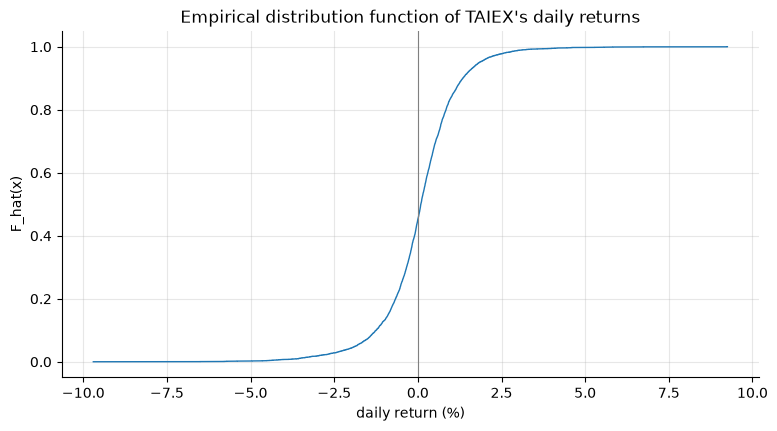

In [5]:
Rs = np.sort(R)
show("F_hat(0)", (R <= 0 + EPS).mean(), ".4f", "0.4520")
show("median %", float(np.median(R)) * 100, ".4f", "0.0879")
show("days above the mean", int((R > Rbar).sum()), ",", "3,020")

rows = []
for u in (0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999):
    j = ceil(u * T - 1e-9)
    inv = np.quantile(R, u, method="inverted_cdf")
    assert inv == Rs[j - 1]
    rows.append({"u": u, "j": j, "F_hat^-1(u) %": round(inv * 100, 3), "np.quantile default %": round(np.quantile(R, u) * 100, 3)})
print(pl.DataFrame(rows))
show("F_hat^-1(0.001) %", np.quantile(R, 0.001, method="inverted_cdf") * 100, ".3f", "-6.313")
show("np.quantile default at 0.001 %", np.quantile(R, 0.001) * 100, ".3f", "-5.866")

fig, ax = plt.subplots()
ax.step(Rs * 100, np.arange(1, T + 1) / T, where="post", lw=1)
ax.axvline(0, color="grey", lw=0.8)
ax.set(xlabel="daily return (%)", ylabel="F_hat(x)", title="Empirical distribution function of TAIEX's daily returns")
plt.show()

## Part 3 — Expectation and LOTUS

Example 3 on the two trades, and Example 4: the growth function as an expectation under $\hat F$. Jensen's inequality (Section 6) predicts $\bar g(f)\le\ln(1+f\bar R)$ at every exposure; the plot shows both.

E[X] = 1.265625 = 1.125^2 = 1.265625
E[half ln X] %: 5.889   [book: 5.889]
half ln E[X] %: 11.778   [book: 11.778]
g_bar(1) = r_bar (bp): 5.5170   [book: 5.5170]
A r_bar %: 13.58   [book: 13.58]
compound rate over the sample %: 14.54   [book: 14.54]


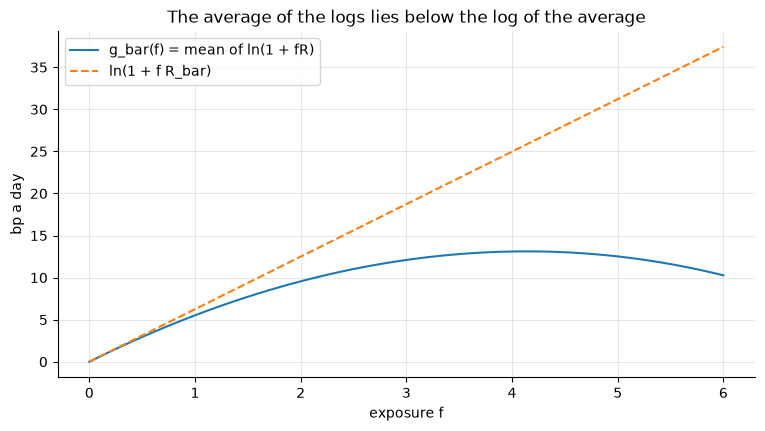

In [6]:
EX = sum(float(p) * v for v, p in zip(values, pX))
E_half = sum(float(p) * 0.5 * log(v) for v, p in zip(values, pX))
print(f"E[X] = {EX} = 1.125^2 = {1.125 ** 2}")
show("E[half ln X] %", E_half * 100, ".3f", "5.889")
show("half ln E[X] %", 0.5 * log(EX) * 100, ".3f", "11.778")

rbar = np.log1p(R).mean()
show("g_bar(1) = r_bar (bp)", rbar * 1e4, ".4f", "5.5170")
show("A r_bar %", A * rbar * 100, ".2f", "13.58")
Gfull = px["price"][-1] / px["price"][0]
show("compound rate over the sample %", (Gfull ** (1 / years) - 1) * 100, ".2f", "14.54")

fs = np.linspace(0, 6, 61)
gbar = np.array([np.log1p(f * R).mean() for f in fs])
fig, ax = plt.subplots()
ax.plot(fs, gbar * 1e4, label="g_bar(f) = mean of ln(1 + fR)")
ax.plot(fs, np.log1p(fs * Rbar) * 1e4, "--", label="ln(1 + f R_bar)")
ax.set(xlabel="exposure f", ylabel="bp a day", title="The average of the logs lies below the log of the average")
ax.legend(); plt.show()

## Part 4 — Moments

The identity (3.7) as (14.4) under $\hat F$, the bet of Example 5, and Exhibit 4: TAIEX against the normal with the same mean and variance. SciPy's `skew` and `kurtosis` use divisor-$T$ moments by default, and `kurtosis` returns the excess kurtosis.

In [7]:
m2, m3, m4 = (R ** 2).mean(), (R ** 3).mean(), (R ** 4).mean()
print(f"(3.7): E[R^2] = {m2:.4e} = s^2 + Rbar^2 = {s ** 2:.4e} + {Rbar ** 2:.4e}")
skew_f = ((R - Rbar) ** 3).mean() / s ** 3
kurt_f = ((R - Rbar) ** 4).mean() / s ** 4
print("skewness: formula", skew_f, "| scipy", stats.skew(R))
print("kurtosis: formula", kurt_f, "| scipy excess + 3", stats.kurtosis(R) + 3)
show("skewness", skew_f, ".3f", "-0.338")
show("kurtosis", kurt_f, ".2f", "8.27")
show("excess kurtosis", stats.kurtosis(R), ".2f", "5.27")

R6, s6 = 0.00062505, 0.01208364              # the six-decimal inputs of the case note
nX = stats.norm(R6, s6)
print(f"normal E[X^3] {nX.moment(3):.3e} (book 2.740e-07), E[X^4] {nX.moment(4):.3e} (book 6.430e-08)")
show("E[R^4] / normal's", m4 / nX.moment(4), ".2f", "2.72")
q2 = (Rbar / s) ** 2                          # the dropped terms of LM4's approximations, as shares
show("(Rbar/s)^2", q2, ".4f", "0.0027")
show("share dropped from 3 mu sigma^2 %", q2 / 3 * 100, ".2f", "0.09")
show("share dropped from 3 sigma^4 %", (2 * q2 + q2 ** 2 / 3) * 100, ".2f", "0.54")
with np.errstate(all="ignore"):
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        print("normal E[ln(1 + X)] by norm.expect:", nX.expect(np.log1p), "(a normal puts mass below -1)")

# the +2%/-1% bet: positive raw third moment, zero skewness, kurtosis 1
bet = np.array([0.02, -0.01])
mu_b = bet.mean()
print("bet: E R^3", (bet ** 3).mean(), "= mu^3 + 3 mu sigma^2", mu_b ** 3 + 3 * mu_b * bet.var(),
      "| skew", stats.skew(bet), "| kurtosis", stats.kurtosis(bet) + 3)

(3.7): E[R^2] = 1.4641e-04 = s^2 + Rbar^2 = 1.4601e-04 + 3.9069e-07
skewness: formula -0.33844417922022413 | scipy -0.33844417922022413
kurtosis: formula 8.268030077423173 | scipy excess + 3 8.26803007742317
skewness: -0.338   [book: -0.338]
kurtosis: 8.27   [book: 8.27]
excess kurtosis: 5.27   [book: 5.27]
normal E[X^3] 2.740e-07 (book 2.740e-07), E[X^4] 6.430e-08 (book 6.430e-08)
E[R^4] / normal's: 2.72   [book: 2.72]
(Rbar/s)^2: 0.0027   [book: 0.0027]
share dropped from 3 mu sigma^2 %: 0.09   [book: 0.09]
share dropped from 3 sigma^4 %: 0.54   [book: 0.54]
normal E[ln(1 + X)] by norm.expect: nan (a normal puts mass below -1)
bet: E R^3 3.5000000000000004e-06 = mu^3 + 3 mu sigma^2 3.5e-06 | skew 0.0 | kurtosis 1.0


## Part 5 — Tail bounds

Exhibit 5 and Exhibit 6: TAIEX's tail days against Chebyshev's $1/k^2$ and Cantelli's $1/(1+k^2)$, then Example 7 and Example 8. Every bound holds for $\hat F$, because $\hat F$ is a probability law with mean $\bar R$ and variance $s^2$.

shape: (6, 7)
┌─────┬────────────────┬─────────┬─────────────┬────────────┬──────────┬────────────┐
│ k   ┆ two-sided days ┆ share % ┆ Chebyshev % ┆ lower days ┆ share %  ┆ Cantelli % │
│ --- ┆ ---            ┆ ---     ┆ ---         ┆ ---        ┆ ---      ┆ ---        │
│ i64 ┆ i64            ┆ f64     ┆ f64         ┆ i64        ┆ f64      ┆ f64        │
╞═════╪════════════════╪═════════╪═════════════╪════════════╪══════════╪════════════╡
│ 1   ┆ 1313           ┆ 22.45   ┆ 100.0       ┆ 665        ┆ 11.37    ┆ 50.0       │
│ 2   ┆ 319            ┆ 5.45    ┆ 25.0        ┆ 188        ┆ 3.21     ┆ 20.0       │
│ 3   ┆ 99             ┆ 1.69    ┆ 11.11       ┆ 61         ┆ 1.04     ┆ 10.0       │
│ 4   ┆ 30             ┆ 0.51    ┆ 6.25        ┆ 17         ┆ 0.29     ┆ 5.88       │
│ 5   ┆ 11             ┆ 0.19    ┆ 4.0         ┆ 6          ┆ 0.1      ┆ 3.85       │
│ 6   ┆ 4              ┆ 0.07    ┆ 2.78        ┆ 2          ┆ 0.03     ┆ 2.7        │
└─────┴────────────────┴─────────┴──────

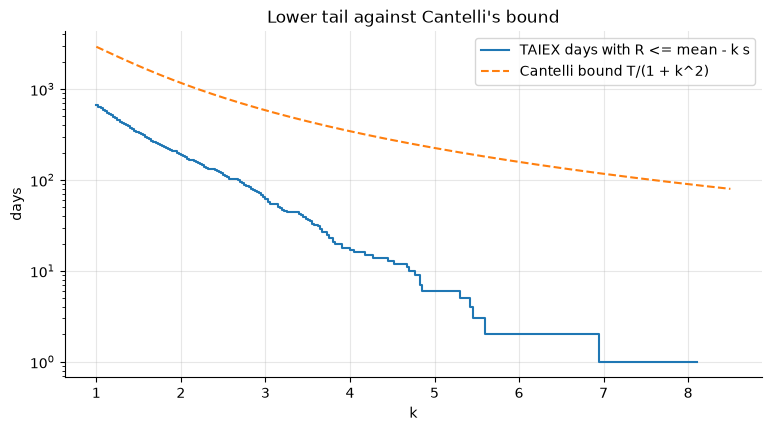

Markov on |R| %: 28.0   [book: 28.0]
Markov on R^2 %: 16.27   [book: 16.27]
days |R| >= 3%: 175   [book: 175]
Cantelli at -3% %: 13.47   [book: 13.47]
days at or below mean - 4s: 17   [book: 17]
normal expected days: 0.185   [book: 0.185]


In [8]:
z = (R - Rbar) / s
rows = []
for k in range(1, 7):
    two = int((np.abs(z) >= k - EPS).sum())
    low = int((z <= -k + EPS).sum())
    rows.append({"k": k, "two-sided days": two, "share %": round(two / T * 100, 2), "Chebyshev %": round(100 / k ** 2, 2),
                 "lower days": low, "share % ": round(low / T * 100, 2), "Cantelli %": round(100 / (1 + k ** 2), 2)})
print(pl.DataFrame(rows))

ks = np.linspace(1, 8.5, 301)
lower = [(z <= -k + EPS).sum() for k in ks]
fig, ax = plt.subplots()
ax.step(ks, np.where(np.array(lower) > 0, lower, np.nan), where="post", label="TAIEX days with R <= mean - k s")
ax.plot(ks, T / (1 + ks ** 2), "--", label="Cantelli bound T/(1 + k^2)")
ax.set_yscale("log"); ax.set(xlabel="k", ylabel="days", title="Lower tail against Cantelli's bound")
ax.legend(); plt.show()

# Example: three bounds for a 3% day
show("Markov on |R| %", np.abs(R).mean() / 0.03 * 100, ".1f", "28.0")
show("Markov on R^2 %", m2 / 0.03 ** 2 * 100, ".2f", "16.27")
show("days |R| >= 3%", int((np.abs(R) >= 0.03 - EPS).sum()), "d", "175")
k3 = (Rbar + 0.03) / s
show("Cantelli at -3% %", 100 / (1 + k3 ** 2), ".2f", "13.47")
# Example: four standard deviations below the mean
show("days at or below mean - 4s", int((z <= -4 + EPS).sum()), "d", "17")
show("normal expected days", T * stats.norm.cdf(-4), ".3f", "0.185")

The bounds cannot be improved for every law: these two-point and three-point laws attain them exactly.

In [9]:
for k in (1.5, 2.0, 4.0):
    # Cantelli: -k with probability 1/(1 + k^2), 1/k otherwise (mean 0, variance 1)
    x = np.array([-k, 1 / k]); p = np.array([1 / (1 + k ** 2), k ** 2 / (1 + k ** 2)])
    # Chebyshev: -k, 0, +k with probabilities 1/(2k^2), 1 - 1/k^2, 1/(2k^2)
    y = np.array([-k, 0.0, k]); q = np.array([1 / (2 * k ** 2), 1 - 1 / k ** 2, 1 / (2 * k ** 2)])
    print(f"k = {k}: Cantelli law mean {p @ x:+.1e}, var {p @ x ** 2:.6f}, Pr(X <= -k) {p[0]:.6f} = 1/(1+k^2) {1 / (1 + k ** 2):.6f}; "
          f"Chebyshev law var {q @ y ** 2:.6f}, Pr(|X| >= k) {q[0] + q[2]:.6f} = 1/k^2 {1 / k ** 2:.6f}")

k = 1.5: Cantelli law mean -5.6e-17, var 1.000000, Pr(X <= -k) 0.307692 = 1/(1+k^2) 0.307692; Chebyshev law var 1.000000, Pr(|X| >= k) 0.444444 = 1/k^2 0.444444
k = 2.0: Cantelli law mean +0.0e+00, var 1.000000, Pr(X <= -k) 0.200000 = 1/(1+k^2) 0.200000; Chebyshev law var 1.000000, Pr(|X| >= k) 0.250000 = 1/k^2 0.250000
k = 4.0: Cantelli law mean +0.0e+00, var 1.000000, Pr(X <= -k) 0.058824 = 1/(1+k^2) 0.058824; Chebyshev law var 1.000000, Pr(|X| >= k) 0.062500 = 1/k^2 0.062500


## Part 6 — Jensen's inequality

The chord of any two-point law: change `b`, `a` and `p` (the widget of Section 6 does the same). Then Example 9, the weighted AM–GM inequality with $w_j=1/23$ on the calendar-year growth factors.

{'mu': 20.135, 'sd': 63.205, 'g': 2.141, 'ln(1+mu)': 18.345, 'R_G': 2.164}


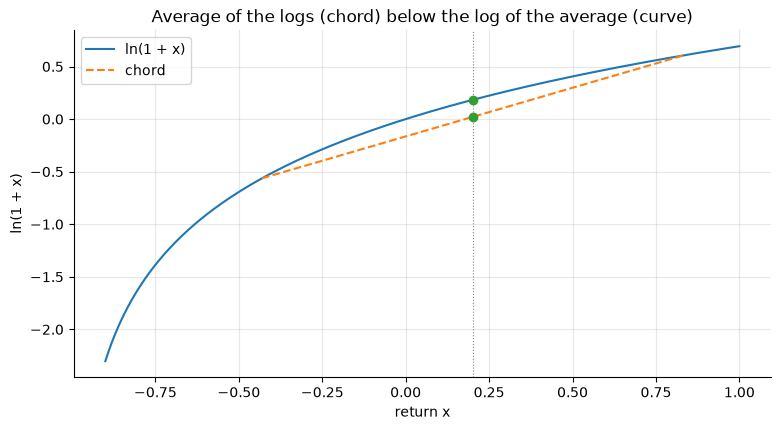

number of calendar years: 23   [book: 23]
arithmetic mean of the growth factors: 1.1497   [book: 1.1497]
geometric mean: 1.1235   [book: 1.1235]


In [10]:
def two_point(b, a, p):
    q = 1 - p
    mu = p * b - q * a
    g = p * log1p(b) + q * log1p(-a)
    return {"mu": mu, "sd": sqrt(p * q) * (a + b), "g": g, "ln(1+mu)": log1p(mu), "R_G": expm1(g)}

b, a, p = 0.8334, 0.4307, 0.5                  # 2008 and 2009, the widget's initial state
L = two_point(b, a, p)
print({k: round(v * 100, 3) for k, v in L.items()})
xs = np.linspace(-0.9, 1.0, 400)
fig, ax = plt.subplots()
ax.plot(xs, np.log1p(xs), label="ln(1 + x)")
ax.plot([-a, b], [log1p(-a), log1p(b)], "--", label="chord")
ax.plot([L["mu"]] * 2, [L["g"], L["ln(1+mu)"]], "o")
ax.axvline(L["mu"], color="grey", lw=0.8, ls=":")
ax.set(xlabel="return x", ylabel="ln(1 + x)", title="Average of the logs (chord) below the log of the average (curve)")
ax.legend(); plt.show()

yr = (px.with_columns(pl.col("date").dt.year().alias("year"))
        .group_by("year", maintain_order=True).agg(pl.col("price").last()).sort("year"))
growth = (yr["price"] / yr["price"].shift(1, fill_value=px["price"][0])).to_numpy()
years_ = yr["year"].to_numpy()
growth = growth[years_ <= 2025]                # 2003 from its first close; 2026 is partial
show("number of calendar years", len(growth), "d", "23")
show("arithmetic mean of the growth factors", growth.mean(), ".4f", "1.1497")
show("geometric mean", np.prod(growth) ** (1 / len(growth)), ".4f", "1.1235")

## Part 7 — Volatility drag and the Jensen gap

Example 10 term by term with (14.13), the rows of Exhibit 7, Exhibit 8 year by year, and the gap at $f=2$.

daily, in bp: {'drag': 0.732, 'sigma^2/2': 0.7301, 'Jensen gap': 0.7316, '2nd': 0.7292, '3rd': 0.002, '4th': 0.0004}
daily Jensen gap bp: 0.7316   [book: 0.7316]
daily drag bp: 0.7320   [book: 0.7320]
shape: (3, 9)
┌───────────────┬─────────┬─────────┬─────────┬───┬────────────┬─────────┬─────────┬────────┐
│ law           ┆ mu %    ┆ sigma % ┆ drag    ┆ … ┆ Jensen gap ┆ 2nd     ┆ 3rd     ┆ 4th    │
│ ---           ┆ ---     ┆ ---     ┆ ---     ┆   ┆ ---        ┆ ---     ┆ ---     ┆ ---    │
│ str           ┆ f64     ┆ f64     ┆ f64     ┆   ┆ f64        ┆ f64     ┆ f64     ┆ f64    │
╞═══════════════╪═════════╪═════════╪═════════╪═══╪════════════╪═════════╪═════════╪════════╡
│ years         ┆ 14.9749 ┆ 23.6984 ┆ 2.6234  ┆ … ┆ 2.3081     ┆ 2.1242  ┆ -0.0542 ┆ 0.2267 │
│ 2008 and 2009 ┆ 20.135  ┆ 63.205  ┆ 17.9707 ┆ … ┆ 16.2034    ┆ 13.8399 ┆ -0.0    ┆ 1.9154 │
│ +100%/-50%    ┆ 25.0    ┆ 75.0    ┆ 25.0    ┆ … ┆ 22.3144    ┆ 18.0    ┆ -0.0    ┆ 3.24   │
└───────────────┴─────────┴──────

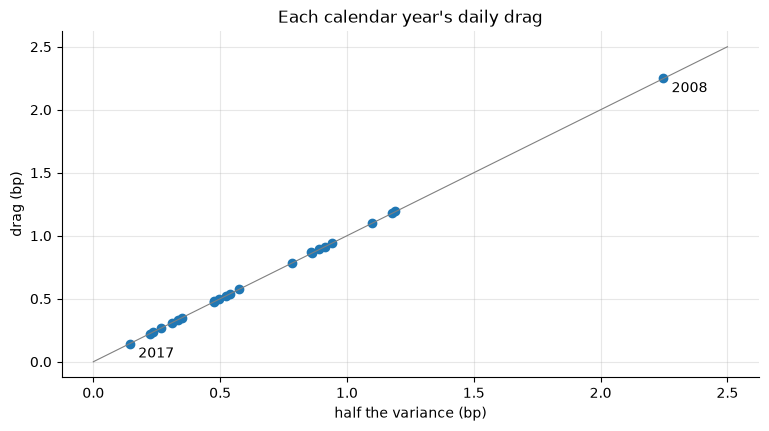

Jensen gap at f = 2 (bp): 2.936   [book: 2.936]


In [11]:
def gap_terms(x, w):
    # Jensen gap ln(1 + mu) - g, drag mu - R_G, sigma^2/2 and the (14.13) terms of order 2, 3 and 4
    mu = w @ x
    y = (x - mu) / (1 + mu)
    g = w @ np.log1p(x)
    return {"mu %": mu * 100, "sigma %": sqrt(w @ (x - mu) ** 2) * 100, "drag": (mu - expm1(g)) * 100,
            "sigma^2/2": (w @ (x - mu) ** 2) / 2 * 100, "Jensen gap": (log1p(mu) - g) * 100,
            "2nd": (w @ y ** 2) / 2 * 100, "3rd": -(w @ y ** 3) / 3 * 100, "4th": (w @ y ** 4) / 4 * 100}

daily = gap_terms(R, np.full(T, 1 / T))
print("daily, in bp:", {k: round(float(v) * 100, 4) for k, v in daily.items() if k not in ("mu %", "sigma %")})
show("daily Jensen gap bp", daily["Jensen gap"] * 100, ".4f", "0.7316")
show("daily drag bp", daily["drag"] * 100, ".4f", "0.7320")
yrs = growth - 1
annual = gap_terms(yrs, np.full(len(yrs), 1 / len(yrs)))
pair = gap_terms(np.array([0.8334, -0.4307]), np.array([0.5, 0.5]))
hm = gap_terms(np.array([1.0, -0.5]), np.array([0.5, 0.5]))
table = pl.DataFrame([{"law": n, **{k: round(v, 4) for k, v in d.items()}}
                      for n, d in (("years", annual), ("2008 and 2009", pair), ("+100%/-50%", hm))])
print(table)
show("annual Jensen gap", annual["Jensen gap"], ".2f", "2.31")
show("annual through the fourth order", annual["2nd"] + annual["3rd"] + annual["4th"], ".2f", "2.30")
show("pair Jensen gap", pair["Jensen gap"], ".2f", "16.20")
show("lognormal form s_r^2/2 bp", np.log1p(R).var() / 2 * 1e4, ".4f", "0.7329")

ry = np.array([d.year for d in dates])
pts = []
for y in range(2003, 2026):
    x = R[ry == y]
    pts.append((y, (x.mean() - expm1(np.log1p(x).mean())) * 1e4, x.var() / 2 * 1e4))
gaps = max((abs(dr - h), y) for y, dr, h in pts)
show("largest |drag - s^2/2| over the years (bp)", gaps[0], ".4f", "0.0097")
fig, ax = plt.subplots()
ax.plot([h for _, _, h in pts], [dr for _, dr, _ in pts], "o")
ax.plot([0, 2.5], [0, 2.5], color="grey", lw=0.8)
for y, dr, h in pts:
    if y in (2008, 2017):
        ax.annotate(str(y), (h, dr), textcoords="offset points", xytext=(6, -10))
ax.set(xlabel="half the variance (bp)", ylabel="drag (bp)", title="Each calendar year's daily drag")
plt.show()

show("Jensen gap at f = 2 (bp)", (log1p(2 * Rbar) - np.log1p(2 * R).mean()) * 1e4, ".3f", "2.936")

## Part 8 — Practice problems

**Problem 2.** The four-day bet of Problem 1: $\E[G]$, $\E[\ln G]$, $\ln\E[G]$ and the Jensen gap.

In [12]:
EG = sum(v * p for v, p in G.items())
ElnG = sum(log(float(v)) * float(p) for v, p in G.items())
assert EG == ((Fraction(102, 100) + Fraction(99, 100)) / 2) ** 4 == Fraction(1005, 1000) ** 4   # binomial theorem
show("E[G]", float(EG), ".5f", "1.02015")
show("E[ln G] %", ElnG * 100, ".5f", "1.95046")
show("ln E[G] %", log(float(EG)) * 100, ".5f", "1.99502")
show("Jensen gap (bp)", (log(float(EG)) - ElnG) * 1e4, ".3f", "4.456")

E[G]: 1.02015   [book: 1.02015]
E[ln G] %: 1.95046   [book: 1.95046]
ln E[G] %: 1.99502   [book: 1.99502]
Jensen gap (bp): 4.456   [book: 4.456]


**Problem 4.** +1% with probability 0.9 and −5% otherwise, at $f=1$ and $f=8$: skewness and kurtosis do not change.

In [13]:
x4, p4 = np.array([0.01, -0.05]), np.array([0.9, 0.1])
for f in (1, 8):
    x = f * x4
    mu = p4 @ x
    sd = sqrt(p4 @ (x - mu) ** 2)
    print(f"f = {f}: mu {mu * 100:.1f}%, sigma {sd * 100:.1f}%, E[R^2] {p4 @ x ** 2:.5f}, E[R^3] {p4 @ x ** 3:.7f}, "
          f"skew {p4 @ ((x - mu) / sd) ** 3:.4f} (-8/3), kurtosis {p4 @ ((x - mu) / sd) ** 4:.4f} (73/9 = {73 / 9:.4f})")

f = 1: mu 0.4%, sigma 1.8%, E[R^2] 0.00034, E[R^3] -0.0000116, skew -2.6667 (-8/3), kurtosis 8.1111 (73/9 = 8.1111)
f = 8: mu 3.2%, sigma 14.4%, E[R^2] 0.02176, E[R^3] -0.0059392, skew -2.6667 (-8/3), kurtosis 8.1111 (73/9 = 8.1111)


**Problem 6.** Cantelli and Chebyshev for $R\le-5\%$ from the printed $\bar R=0.0625\%$ and $s=1.2084\%$.

In [14]:
k6 = (0.0625 + 5) / 1.2084
show("k", k6, ".4f", "4.1894")
show("Cantelli %", 100 / (1 + 4.1894 ** 2), ".2f", "5.39")
show("Chebyshev %", 100 / 4.1894 ** 2, ".2f", "5.70")
show("days at or below -5%", int((R <= -0.05 + EPS).sum()), "d", "15")

k: 4.1894   [book: 4.1894]
Cantelli %: 5.39   [book: 5.39]
Chebyshev %: 5.70   [book: 5.70]
days at or below -5%: 15   [book: 15]


**Problem 10.** The calendar years from their printed moments: (3.9) against (14.13) through the fourth order.

In [15]:
mp, sp, skp, kup = 0.1497, 0.2370, 0.19, 5.02
t2 = sp ** 2 / (2 * (1 + mp) ** 2)
t3 = -skp * sp ** 3 / (3 * (1 + mp) ** 3)
t4 = kup * sp ** 4 / (4 * (1 + mp) ** 4)
show("(3.9) %", (mp - sp ** 2 / 2) * 100, ".2f", "12.16")
print(f"terms {t2 * 100:.4f}, {t3 * 100:.4f}, {t4 * 100:.4f}; sum {(t2 + t3 + t4) * 100:.4f}")
show("R_G, second-order term alone %", ((1 + mp) * exp(-t2) - 1) * 100, ".2f", "12.55")
show("R_G, second- and fourth-order terms %", ((1 + mp) * exp(-(t2 + t4)) - 1) * 100, ".2f", "12.30")
show("R_G through the fourth order %", ((1 + mp) * exp(-(t2 + t3 + t4)) - 1) * 100, ".2f", "12.36")
show("actual compound rate %", (np.prod(growth) ** (1 / len(growth)) - 1) * 100, ".2f", "12.35")
# (3.9) subtracts sigma^2/2 as the drag; the drag (1 + mu)(1 - e^-gap) has the leading term sigma^2/(2(1 + mu))
show("(3.9)'s drag sigma^2/2 (points)", sp ** 2 / 2 * 100, ".2f", "2.81")
show("drag's leading term sigma^2/(2(1 + mu)) (points)", sp ** 2 / (2 * (1 + mp)) * 100, ".2f", "2.44")
show("actual drag (points)", annual["drag"], ".2f", "2.62")

(3.9) %: 12.16   [book: 12.16]
terms 2.1247, -0.0555, 0.2266; sum 2.2958
R_G, second-order term alone %: 12.55   [book: 12.55]
R_G, second- and fourth-order terms %: 12.30   [book: 12.30]
R_G through the fourth order %: 12.36   [book: 12.36]
actual compound rate %: 12.35   [book: 12.35]
(3.9)'s drag sigma^2/2 (points): 2.81   [book: 2.81]
drag's leading term sigma^2/(2(1 + mu)) (points): 2.44   [book: 2.44]
actual drag (points): 2.62   [book: 2.62]


**Problem 11.** $T$, $A$, $\bar R$, $s$ and (3.7) are in Part 1 and Part 4; the quantile in Part 2; the counts at $k=2,3,4$ and the Jensen gap's terms below.

In [16]:
for k in (2, 3, 4):
    print(f"k = {k}: two-sided {int((np.abs(z) >= k - EPS).sum())}, lower {int((z <= -k + EPS).sum())}")
print(f"Jensen gap {daily['Jensen gap'] * 100:.4f} bp = {daily['2nd'] * 100:.4f} + {daily['3rd'] * 100:.4f} + "
      f"{daily['4th'] * 100:.4f} (through the fourth order)")

k = 2: two-sided 319, lower 188
k = 3: two-sided 99, lower 61
k = 4: two-sided 30, lower 17
Jensen gap 0.7316 bp = 0.7292 + 0.0020 + 0.0004 (through the fourth order)


### Extension: the two price-limit regimes (a stability check)

The daily limit was 7% until 29 May 2015 and 10% from 1 June 2015. Split the sample there and recompute, within each regime and with its own $\bar R$ and $s$: the drag $\bar R-R_G$, the Jensen gap and its three terms, and the days at or below $\bar R-4s$. This is a stability check of a description, not a test, so draw no conclusion from it. LM15 compares the kurtosis of the two regimes.

In [17]:
cut = np.array([d.isoformat() <= "2015-05-29" for d in dates])
for name, mask in (("7% limit, to 2015-05-29", cut), ("10% limit, from 2015-06-01", ~cut)):
    x = R[mask]
    t = gap_terms(x, np.full(len(x), 1 / len(x)))
    zz = (x - x.mean()) / x.std()
    print(f"{name}: T = {len(x)}, drag {t['drag'] * 100:.4f} bp, Jensen gap {t['Jensen gap'] * 100:.4f} bp "
          f"(terms {t['2nd'] * 100:.4f}, {t['3rd'] * 100:.4f}, {t['4th'] * 100:.4f}), "
          f"days at or below mean - 4s: {int((zz <= -4 + EPS).sum())}")
# your code: does the second-order term describe each regime's gap as well as it describes the full sample?

7% limit, to 2015-05-29: T = 3077, drag 0.7919 bp, Jensen gap 0.7916 bp (terms 0.7893, 0.0018, 0.0004), days at or below mean - 4s: 8
10% limit, from 2015-06-01: T = 2772, drag 0.6652 bp, Jensen gap 0.6647 bp (terms 0.6621, 0.0021, 0.0005), days at or below mean - 4s: 10
